# 04 · Fusion: posterior traces of the scripted replays

**Synthetic.** Every piece of evidence is scripted in `configs/fusion_scenarios/*.yaml` (camera alarms at real camera sites, calls placed by an offset from a camera, operator reviews) and replayed on the Pune road network by
`uv run python -m resqcity.sim.fusion_replay --all`, which writes `results/fusion/replay_<name>_synthetic.json`. This notebook only reads those files.

Model: `docs/models/fusion.md` (D-028). Detector inputs are measured (`results/vision/sim_inputs.yaml`); call and review parameters are UNVERIFIED (`configs/calls.yaml`, `configs/fusion.yaml`). The traces illustrate the model; they are not research results.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from resqcity.common.config import CONFIG_DIR, PROJECT_ROOT

RESULTS = PROJECT_ROOT / 'results' / 'fusion'
SCENARIOS = CONFIG_DIR / 'fusion_scenarios'
ORDER = sorted(p.stem for p in SCENARIOS.glob('*.yaml'))  # every scenario, never a subset
runs = {n: json.loads((RESULTS / f'replay_{n}_synthetic.json').read_text(encoding='utf-8'))
        for n in ORDER}
scripts = {n: yaml.safe_load((SCENARIOS / f'{n}.yaml').read_text(encoding='utf-8'))
           for n in ORDER}
rows = []
for n, r in runs.items():
    for inc, v in r['incidents'].items():
        rows.append({'scenario': n, 'grouping_ok': r['grouping_ok'], 'incident': inc,
                     'sources': len(v['sources']), 'final_posterior': v['posterior'],
                     'type': v['type'], 'ambulance': v['requirements']['ambulance'],
                     'police': v['requirements']['police'],
                     'fire': v['requirements']['fire']})
table = pd.DataFrame(rows)
table.style.format({'final_posterior': '{:.3g}'})

,scenario,grouping_ok,incident,sources,final_posterior,type,ambulance,police,fire
0,alarm_confirmed_then_call,True,INC-000001,3,0.99,accident,2,1,1
1,false_alarm_rejected,True,INC-000001,2,9.99e-08,accident,1,1,0
2,prank_call,True,INC-000001,1,0.468,fire_smoke,0,1,1
3,two_crashes,True,INC-000001,2,1,accident,1,1,0
4,two_crashes,True,INC-000002,2,1,accident,0,1,0
5,two_crashes_merged,True,INC-000001,2,1,accident,2,1,1
6,two_crashes_near,True,INC-000001,2,1,accident,1,1,0
7,two_crashes_near,True,INC-000002,2,1,accident,0,1,0
8,two_views_one_crash,True,INC-000001,4,1,accident,1,1,0


Posterior after each piece of evidence and at the end (table view of the figure below):

In [2]:
steps = []
for n, r in runs.items():
    trace = pd.DataFrame(r['trace'])
    for it in sorted(scripts[n]['evidence'], key=lambda e: e['t']):
        inc = r['evidence_to_incident'][it['id']]
        at = trace[(trace.candidate == inc) & (trace.t_s == it['t'])]
        steps.append({'scenario': n, 't_s': it['t'], 'evidence': it['id'],
                      'kind': it['kind'], 'incident': inc,
                      'posterior_after': at.posterior.iloc[-1]})
pd.DataFrame(steps).style.format({'posterior_after': '{:.3g}'})

,scenario,t_s,evidence,kind,incident,posterior_after
0,alarm_confirmed_then_call,0,EV-C,camera,INC-000001,3.43e-05
1,alarm_confirmed_then_call,40,REV-C,review,INC-000001,0.00157
2,alarm_confirmed_then_call,200,CALL-C,call,INC-000001,0.996
3,false_alarm_rejected,0,EV-F,camera,INC-000001,1.23e-05
4,false_alarm_rejected,40,REV-F,review,INC-000001,6.08e-07
5,prank_call,0,CALL-P,call,INC-000001,0.706
6,two_crashes,120,CALL-A1,call,INC-000001,0.706
7,two_crashes,180,CALL-B1,call,INC-000002,0.651
8,two_crashes,240,CALL-A2,call,INC-000001,1
9,two_crashes,300,CALL-B2,call,INC-000002,1


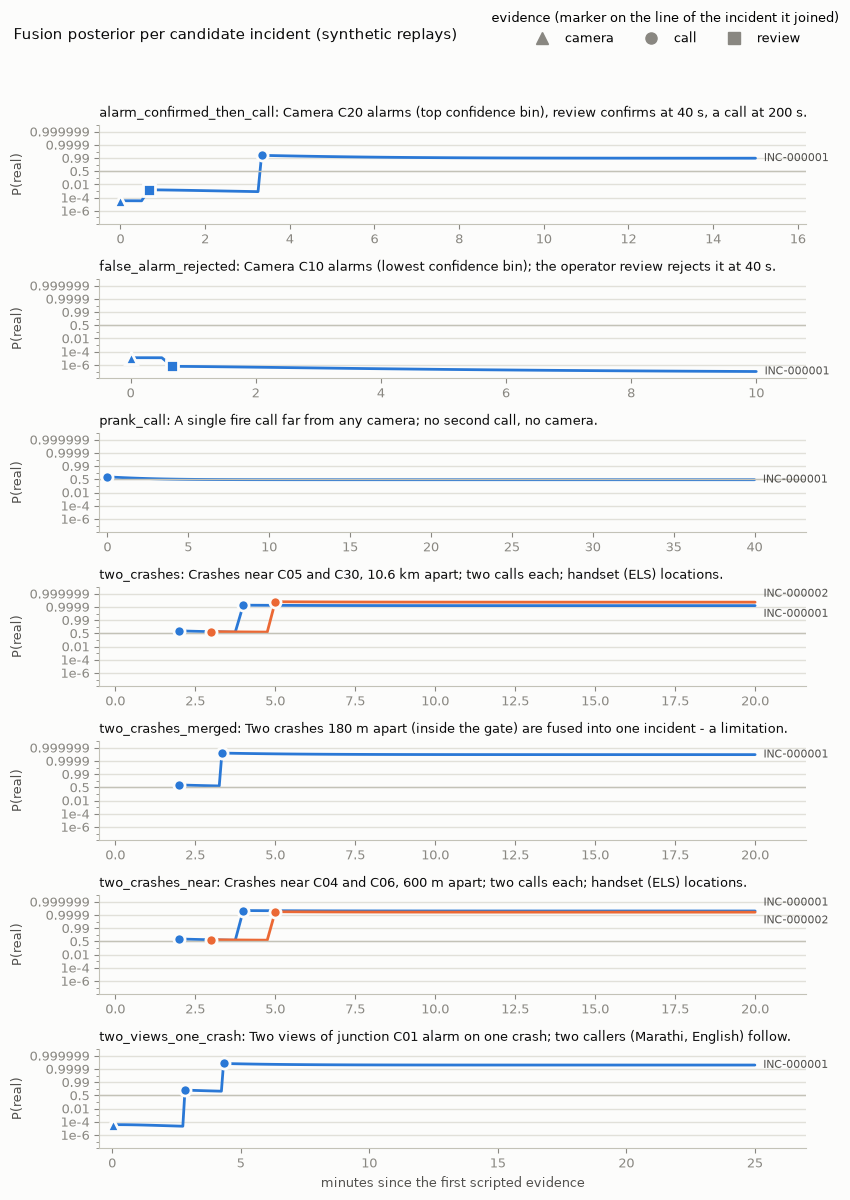

In [3]:
# Palette: reference categorical slots 1-2 (validated light-mode pair), text and grid
# neutrals; logit y-axis because posteriors span 1e-7 .. 1 - 1e-5 (axis 1e-8 .. 1 - 1e-7).(axis 1e-8 .. 1 - 1e-7).
SERIES = ['#2a78d6', '#eb6834']
SURFACE, TEXT, TEXT2, MUTED, GRID, AXIS = ('#fcfcfb', '#0b0b0b', '#52514e', '#898781',
                                          '#e1e0d9', '#c3c2b7')
MARK = {'camera': '^', 'call': 'o', 'review': 's'}
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': AXIS, 'axes.labelcolor': TEXT2,
                     'xtick.color': MUTED, 'ytick.color': MUTED,
                     'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE})
fig, axes = plt.subplots(len(ORDER), 1, figsize=(8.5, 12), sharey=True)
for ax, n in zip(axes, ORDER):
    r, sc = runs[n], scripts[n]
    trace = pd.DataFrame(r['trace']).drop_duplicates(['candidate', 't_s'], keep='last')
    finals = trace.sort_values('t_s').groupby('candidate').posterior.last()
    order = list(finals.sort_values(ascending=False).index)  # label offsets: top line up
    rank = {c: 0 if len(order) == 1 else 6 - 12 * i for i, c in enumerate(order)}
    for k, (inc, g) in enumerate(trace.groupby('candidate', sort=True)):
        color = SERIES[k]
        g = g.sort_values('t_s')
        ax.plot(g.t_s / 60, g.posterior, color=color, lw=2, solid_capstyle='round')
        for it in sc['evidence']:
            if r['evidence_to_incident'].get(it['id']) != inc:
                continue
            p = g[g.t_s == it['t']].posterior.iloc[-1]
            ax.plot(it['t'] / 60, p, MARK[it['kind']], ms=8, color=color,
                    markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
        last = g.iloc[-1]
        ax.annotate(inc, (last.t_s / 60, last.posterior), xytext=(6, rank[inc]),
                    textcoords='offset points', va='center', color=TEXT2, fontsize=8)
    ax.set_yscale('logit')
    ax.set_ylim(1e-8, 1 - 1e-7)
    ax.set_yticks([1e-6, 1e-4, 1e-2, 0.5, 0.99, 0.9999, 0.999999])
    ax.set_yticklabels(['1e-6', '1e-4', '0.01', '0.5', '0.99', '0.9999', '0.999999'])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.axhline(0.5, color=AXIS, lw=1)
    ax.grid(axis='y', color=GRID, lw=1)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.set_xlim(-0.5, sc['end_s'] / 60 * 1.08)
    ax.set_title(f"{n}: {sc['description']}", loc='left', color=TEXT, fontsize=9)
    ax.set_ylabel('P(real)')
axes[-1].set_xlabel('minutes since the first scripted evidence')
handles = [plt.Line2D([], [], marker=m, ls='', color=MUTED, ms=8, label=k)
           for k, m in MARK.items()]
fig.legend(handles=handles, loc='upper right', frameon=False, ncol=3,
           title='evidence (marker on the line of the incident it joined)')
fig.suptitle('Fusion posterior per candidate incident (synthetic replays)', x=0.02,
             ha='left', color=TEXT, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

How to read it (qualitative; the values are in the tables above):

- A camera alarm alone stays near the bottom of the scale: the measured detector raises many false alarms per camera-hour and a camera rarely sees a real crash (D-028).
- A call alone lands near the middle: the ratio of genuine first calls to false calls.
- A call at the typical delay after a camera alarm counts more than the same call alone, because the camera pins the onset (point-process call model, `docs/models/fusion.md` §3.2); a second caller makes the incident near-certain.
- An operator review moves a camera-only candidate by its likelihood ratio, but with the UNVERIFIED specificity it cannot by itself lift a camera alarm to a dispatch level.
- Without further evidence a candidate loses belief over time and is dismissed after `update.expiry_s`.
- `two_crashes_near` is the real discrimination test: two crashes 600 m apart — the closest any two camera sites get — stay separate, because the gate for handset-located calls is 362 m. `two_crashes_merged` shows the **limitation**: at 180 m, inside the gate, two genuinely separate crashes are fused into one incident and the model has no way to split them again (`docs/models/fusion.md` §5, assumption 3). `two_crashes` at 10.6 km is a sanity check only.